In [1]:
import pandas as pd
dtset = pd.read_csv("processedPlacementData.csv")

# Quantitative columns
quan = dtset.select_dtypes(include=['number']).columns

# Qualitative columns
qual = dtset.select_dtypes(include=['object', 'category']).columns

dtset.isnull().sum()


ssc_p             0
hsc_p             0
degree_p          0
etest_p           0
mba_p             0
salary            0
gender            0
ssc_b             0
hsc_b             0
hsc_s             0
degree_t          0
workex            0
specialisation    0
status            0
dtype: int64

In [2]:
import seaborn as sn

C:\Users\ssiva\AppData\Local\Temp\ipykernel_10328\173919008.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sn.distplot(dtset["ssc_p"])


<Axes: xlabel='ssc_p', ylabel='Density'>

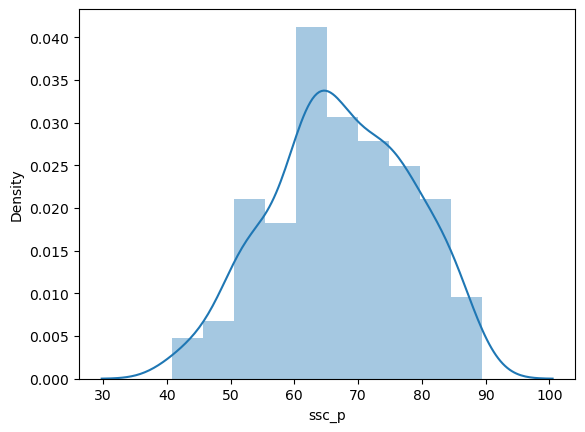

In [3]:
sn.distplot(dtset["ssc_p"])

In [16]:
def get_pdf_prob(dtColumn, startRange, endRange):
    from matplotlib import pyplot
    from scipy.stats import norm
    import seaborn as sn

    ax = sn.histplot(dtColumn, kde=True, color="green")
    pyplot.axvline(startRange, color="red")
    pyplot.axvline(endRange, color="red")

    sample_mean = dtColumn.mean()
    sample_std = dtColumn.std()

    print("Mean is:", sample_mean )
    print("Standard Deviation is:", sample_std )

    disp = norm(sample_mean, sample_std)

    cdf_prob = disp.cdf(endRange) - disp.cdf(startRange)
    return cdf_prob
    
    
    

Mean is: 67.30339534883721
Standard Deviation is: 10.827205398231452
PDF for the given range is: 0.8245275716761188


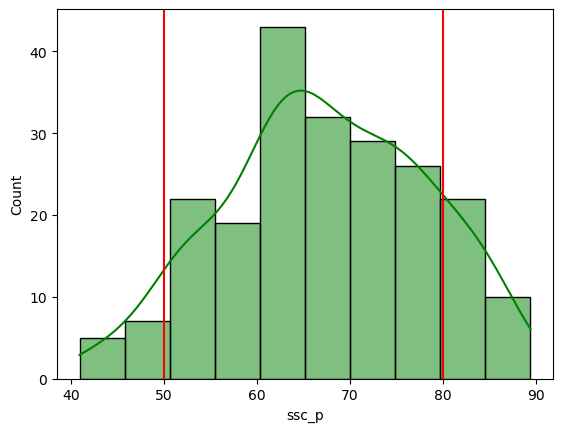

In [18]:
prob1 = get_pdf_prob(dtset["ssc_p"],50, 80)
print("PDF for the given range is:", prob1 )

In [8]:
# !pip install scipy

In [25]:
from statsmodels.distributions.empirical_distribution import ECDF
ecdf = ECDF(dtset["ssc_p"])
ecdf(60)            

np.float64(0.24186046511627907)

In [29]:
def get_zscore(dtset, columnName):
    import seaborn as sn
    import matplotlib.pyplot as plt
    from scipy.stats import zscore

    score = zscore(dtset[columnName].dropna())

    sn.histplot(score, kde=True)
    plt.title("Z-score Distribution of " + columnName)
    plt.show()

    print("Mean of Z-scores:", score.mean())
    print("Number of Z-scores:", len(score))

    return score

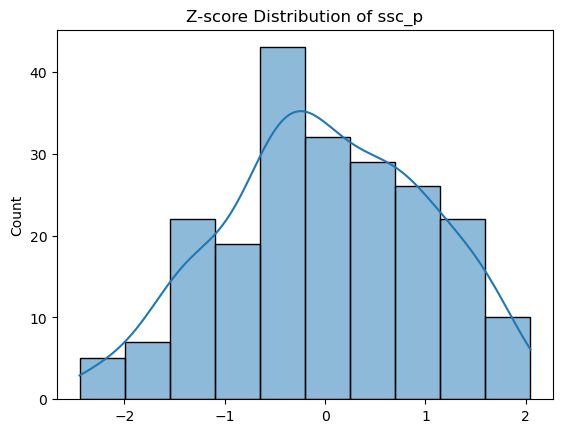

Mean of Z-scores: -3.9658199205214894e-16
Number of Z-scores: 215


array([-2.44523273, -2.43504942, -2.24989846, -2.15732299, -2.06474751,
       -1.97217203, -1.87959655, -1.87959655, -1.78702107, -1.69444559,
       -1.69444559, -1.60187011, -1.50929463, -1.50929463, -1.45652661,
       -1.41671915, -1.41671915, -1.41671915, -1.41671915, -1.41671915,
       -1.41671915, -1.41671915, -1.41671915, -1.41671915, -1.36302538,
       -1.36117387, -1.32414368, -1.2315682 , -1.2315682 , -1.2315682 ,
       -1.2130531 , -1.194538  , -1.13899272, -1.13899272, -1.08344743,
       -1.07604139, -1.04641724, -1.0204961 , -0.99087195, -0.86126628,
       -0.86126628, -0.86126628, -0.86126628, -0.86126628, -0.86126628,
       -0.7686908 , -0.7686908 , -0.7686908 , -0.71314551, -0.67981834,
       -0.67611532, -0.67611532, -0.65482296, -0.63908513, -0.60205494,
       -0.58353984, -0.58353984, -0.58353984, -0.58353984, -0.57613381,
       -0.50947946, -0.49096436, -0.49096436, -0.49096436, -0.49096436,
       -0.49096436, -0.49096436, -0.49096436, -0.49096436, -0.49

In [30]:
zc = get_zscore(dtset, "ssc_p")
zc